In [1]:

import math

# Input and target class
x = [1.0, -1.0]
target = 0

# First layer: weights and biases
W = [[1.0, 1.0, 1.0],
     [-1.0, -1.0, -1.0]]
b = [0.0, 0.0, 0.0]

# Second layer: weights and biases
V = [[1.0, 1.0],
     [-1.0, -1.0],
     [-1.0, -1.0]]
c = [0.0, 0.0]


# Forward pass

# First linear layer
k = [sum(x[i] * W[i][j] for i in range(2)) + b[j]
     for j in range(3)]

# Sigmoid activation
h = [1.0 / (1.0 + math.exp(-k[j])) for j in range(3)]

# Second linear layer
o = [sum(h[j] * V[j][q] for j in range(3)) + c[q]
     for q in range(2)]

# Softmax activation
exp_o = [math.exp(o[q] - max(o)) for q in range(2)]
y = [exp_o[q] / sum(exp_o) for q in range(2)]

# Cross-entropy loss
loss = -math.log(y[target])


# Backward pass

# Gradient of loss w.r.t. output logits
do = y.copy()
do[target] -= 1.0

# Gradients of second-layer weights and biases
dV = [[h[j] * do[q] for q in range(2)]
      for j in range(3)]
dc = do.copy()

# Backpropagate through second linear layer
dh = [sum(V[j][q] * do[q] for q in range(2))
      for j in range(3)]

# Backpropagate through sigmoid
dk = [dh[j] * h[j] * (1.0 - h[j])
      for j in range(3)]

# Gradients of first-layer weights and biases
dW = [[x[i] * dk[j] for j in range(3)]
      for i in range(2)]
db = dk.copy()


# Results
print("Loss:", round(loss, 6))
print("dW:", [[round(v, 4) for v in row] for row in dW])
print("db:", [round(v, 4) for v in db])
print("dV:", [[round(v, 4) for v in row] for row in dV])
print("dc:", [round(v, 4) for v in dc])

Loss: 0.693147
dW: [[0.0, 0.0, 0.0], [-0.0, -0.0, -0.0]]
db: [0.0, 0.0, 0.0]
dV: [[-0.4404, 0.4404], [-0.4404, 0.4404], [-0.4404, 0.4404]]
dc: [-0.5, 0.5]


In [2]:
# -- assignment 1 --
import numpy as np
from urllib import request
import gzip
import pickle
import os

def load_synth(num_train=60_000, num_val=10_000, seed=0):
    """
    Load some very basic synthetic data that should be easy to classify. Two features, so that we can plot the
    decision boundary (which is an ellipse in the feature space).

    :param num_train: Number of training instances
    :param num_val: Number of test/validation instances
    :param num_features: Number of features per instance

    :return: Two tuples and an integer: (xtrain, ytrain), (xval, yval), num_cls. The first contains a matrix of training
     data with 2 features as a numpy floating point array, and the corresponding classification labels as a numpy
     integer array. The second contains the test/validation data in the same format. The last integer contains the
     number of classes (this is always 2 for this function).
    """
    np.random.seed(seed)

    THRESHOLD = 0.6
    quad = np.asarray([[1, -0.05], [1, .4]])

    ntotal = num_train + num_val

    x = np.random.randn(ntotal, 2)

    # compute the quadratic form
    q = np.einsum('bf, fk, bk -> b', x, quad, x)
    y = (q > THRESHOLD).astype(int)

    return (x[:num_train, :], y[:num_train]), (x[num_train:, :], y[num_train:]), 2

def load_mnist(final=False, flatten=True, shuffle_seed=0):
    """
    Load the MNIST data.

    :param final: If true, return the canonical test/train split. If false, split some validation data from the training
       data and keep the test data hidden.
    :param flatten: If true, each instance is flattened into a vector, so that the data is returns as a matrix with 768
        columns. If false, the data is returned as a 3-tensor preserving each image as a matrix.
    :param shuffle_seed If >= 0, the data is shuffled. This keeps the canonical test/train split, but shuffles each
        internally before splitting off a validation set. The given number is used as a seed. Note that the original data
        is _not_ shuffled, but ordered by writer. This means that there will be a distribution shift between train and val
        if the data is not shuffled.

    :return: Two tuples and an integer: (xtrain, ytrain), (xval, yval), num_cls. The first contains a matrix of training
     data and the corresponding classification labels as a numpy integer array. The second contains the test/validation
     data in the same format. The last integer contains the number of classes (this is always 2 for this function).

     """

    if not os.path.isfile('mnist.pkl'):
        init()

    xtrain, ytrain, xtest, ytest = load()
    xtl, xsl = xtrain.shape[0], xtest.shape[0]

    if flatten:
        xtrain = xtrain.reshape(xtl, -1)
        xtest  = xtest.reshape(xsl, -1)

    if shuffle_seed >= 0:
        rng = np.random.default_rng(shuffle_seed)

        p = rng.permutation(xtrain.shape[0])
        xtrain, ytrain = xtrain[p], ytrain[p]

        p = rng.permutation(xtest.shape[0])
        xtest, ytest = xtest[p], ytest[p]

    if not final: # return the flattened images
        return (xtrain[:-5000], ytrain[:-5000]), (xtrain[-5000:], ytrain[-5000:]), 10

    return (xtrain, ytrain), (xtest, ytest), 10

# Numpy-only MNIST loader. Courtesy of Hyeonseok Jung
# https://github.com/hsjeong5/MNIST-for-Numpy

filename = [
["training_images","train-images-idx3-ubyte.gz"],
["test_images","t10k-images-idx3-ubyte.gz"],
["training_labels","train-labels-idx1-ubyte.gz"],
["test_labels","t10k-labels-idx1-ubyte.gz"]
]

def download_mnist():
    base_url = "https://peterbloem.nl/files/mnist/" # "http://yann.lecun.com/exdb/mnist/"
    for name in filename:
        print("Downloading "+name[1]+"...")
        request.urlretrieve(base_url+name[1], name[1])
    print("Download complete.")

def save_mnist():
    mnist = {}
    for name in filename[:2]:
        with gzip.open(name[1], 'rb') as f:
            mnist[name[0]] = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1,28*28)
    for name in filename[-2:]:
        with gzip.open(name[1], 'rb') as f:
            mnist[name[0]] = np.frombuffer(f.read(), np.uint8, offset=8)
    with open("mnist.pkl", 'wb') as f:
        pickle.dump(mnist,f)
    print("Save complete.")

def init():
    download_mnist()
    save_mnist()

def load():
    with open("mnist.pkl",'rb') as f:
        mnist = pickle.load(f)
    return mnist["training_images"], mnist["training_labels"], mnist["test_images"], mnist["test_labels"]


In [4]:
import math
import random

(xtrain, ytrain), (xval, yval), num_cls = load_synth(
    num_train=6000, num_val=1000
)

random.seed(0)
W = [[random.gauss(0, 0.5) for _ in range(3)] for _ in range(2)]
b = [0.] * 3
V = [[random.gauss(0, 0.5) for _ in range(num_cls)]
     for _ in range(3)]
c = [0.] * num_cls

lr = 0.03

for epoch in range(8):
    total_loss = 0

    for x, target in zip(xtrain, ytrain):
        # Forward pass
        k = [sum(x[i]*W[i][j] for i in range(2)) + b[j]
             for j in range(3)]
        h = [1/(1 + math.exp(-v)) for v in k]
        o = [sum(h[j]*V[j][i] for j in range(3)) + c[i]
             for i in range(num_cls)]
        e = [math.exp(v - max(o)) for v in o]
        y = [v/sum(e) for v in e]
        total_loss -= math.log(y[target])

        # Backward pass
        do = [y[i] - (i == target) for i in range(num_cls)]
        dh = [sum(V[j][i]*do[i] for i in range(num_cls))
              for j in range(3)]
        dk = [dh[j]*h[j]*(1-h[j]) for j in range(3)]

        # SGD updates
        for j in range(3):
            for i in range(num_cls):
                V[j][i] -= lr*h[j]*do[i]
        for i in range(num_cls):
            c[i] -= lr*do[i]
        for i in range(2):
            for j in range(3):
                W[i][j] -= lr*x[i]*dk[j]
        for j in range(3):
            b[j] -= lr*dk[j]

    print(f"Epoch {epoch+1}: {total_loss/len(xtrain):.4f}")


Epoch 1: 0.6069
Epoch 2: 0.2449
Epoch 3: 0.1771
Epoch 4: 0.1345
Epoch 5: 0.1183
Epoch 6: 0.1106
Epoch 7: 0.1055
Epoch 8: 0.1017


In [6]:

# Load and normalize MNIST
(xtrain, ytrain), (xval, yval), num_cls = load_mnist()
xtrain = xtrain.astype(float) / 255.0

# Initialize weights and biases
W = np.random.randn(784, 300) * 0.01
b = np.zeros(300)
V = np.random.randn(300, 10) * 0.01
c = np.zeros(10)

# Single image and target
x, target = xtrain[0], ytrain[0]

# Forward pass
k = x @ W + b
h = 1 / (1 + np.exp(-k))
o = h @ V + c
e = np.exp(o - np.max(o))
y = e / np.sum(e)
loss = -np.log(y[target])


Download complete.
Save complete.


In [7]:
print("Predicted probabilities:", np.round(y, 4))
print("Predicted digit:", np.argmax(y))
print("Actual digit:", target)
print("Loss:", round(loss, 4))

Predicted probabilities: [0.0908 0.1041 0.1008 0.095  0.1004 0.1054 0.0906 0.0957 0.0958 0.1213]
Predicted digit: 9
Actual digit: 1
Loss: 2.2628


Epoch 1: 0.3369
Epoch 2: 0.1375
Epoch 3: 0.0934
Epoch 4: 0.0689
Epoch 5: 0.0540


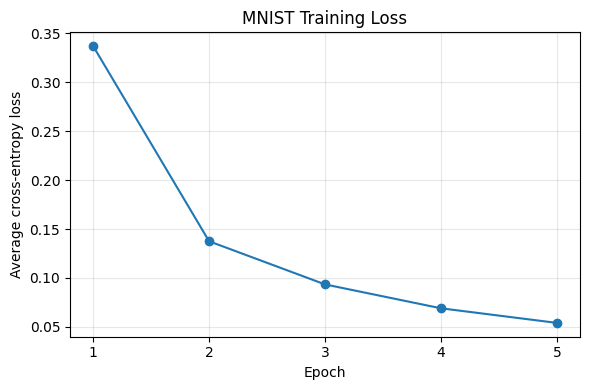

In [10]:
import matplotlib.pyplot as plt

# Load and normalize MNIST
(xtrain, ytrain), (xval, yval), num_cls = load_mnist()
xtrain = xtrain.astype(float) / 255.0

# Initialize network (784 -> 300 -> 10)
np.random.seed(0)
W = np.random.randn(784, 300) * 0.01
b = np.zeros(300)
V = np.random.randn(300, 10) * 0.01
c = np.zeros(10)

# Training
lr = 0.03
epochs = 5
losses = []

for epoch in range(epochs):
    total_loss = 0

    for idx in np.random.permutation(len(xtrain)):
        x, target = xtrain[idx], ytrain[idx]

        # Forward pass
        k = x @ W + b
        h = 1 / (1 + np.exp(-k))
        o = h @ V + c
        e = np.exp(o - np.max(o))
        y = e / np.sum(e)
        total_loss -= np.log(max(y[target], 1e-15))

        # Vectorized backward pass
        do = y.copy()
        do[target] -= 1
        dV = np.outer(h, do)
        dc = do.copy()

        dh = V @ do
        dk = dh * h * (1 - h)
        dW = np.outer(x, dk)
        db = dk.copy()

        # SGD updates
        W -= lr * dW
        b -= lr * db
        V -= lr * dV
        c -= lr * dc

    avg_loss = total_loss / len(xtrain)
    losses.append(avg_loss)
    print(f"Epoch {epoch+1}: {avg_loss:.4f}")

# Plot training loss
plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), losses, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("MNIST Training Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("q6_loss.png", dpi=300)
plt.show()


Epoch 1: 2.0345
Epoch 2: 0.9546
Epoch 3: 0.5855
Epoch 4: 0.4693
Epoch 5: 0.4141


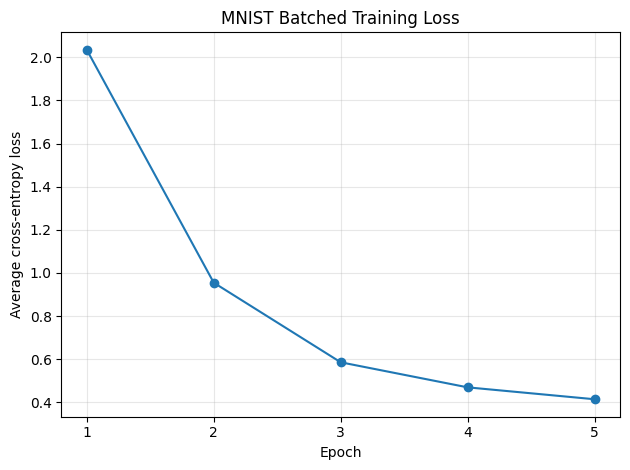

In [11]:

(xtrain, ytrain), (xval, yval), num_cls = load_mnist()
xtrain = xtrain.astype(np.float32) / 255.0

rng = np.random.default_rng(0)
W = rng.normal(0, 0.01, (xtrain.shape[1], 300))
b = np.zeros(300)
V = rng.normal(0, 0.01, (300, num_cls))
c = np.zeros(num_cls)

lr, batch_size, epochs = 0.03, 64, 5
losses = []

for epoch in range(epochs):
    indices = rng.permutation(len(xtrain))
    total_loss = 0.0

    for start in range(0, len(xtrain), batch_size):
        batch = indices[start:start + batch_size]
        X, t = xtrain[batch], ytrain[batch]
        m = len(t)

        # Batched forward pass
        K = X @ W + b
        H = 1 / (1 + np.exp(-K))
        O = H @ V + c
        E = np.exp(O - O.max(axis=1, keepdims=True))
        Y = E / E.sum(axis=1, keepdims=True)
        total_loss -= np.log(
            np.maximum(Y[np.arange(m), t], 1e-15)
        ).sum()

        # Batched backward pass
        DO = Y.copy()
        DO[np.arange(m), t] -= 1
        DO /= m

        dV = H.T @ DO
        dc = DO.sum(axis=0)
        DK = (DO @ V.T) * H * (1 - H)
        dW = X.T @ DK
        db = DK.sum(axis=0)

        # SGD updates
        W -= lr * dW
        b -= lr * db
        V -= lr * dV
        c -= lr * dc

    losses.append(total_loss / len(xtrain))
    print(f"Epoch {epoch + 1}: {losses[-1]:.4f}")

# Loss plot
plt.plot(range(1, epochs + 1), losses, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("MNIST Batched Training Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("q7_loss.png", dpi=300)
plt.show()


In [13]:
EPOCHS, BATCH_SIZE = 5, 64
RATES = [0.001, 0.003, 0.01, 0.03]
SEEDS = [0, 1, 2]


def prepare(x):
    x = np.asarray(x, dtype=np.float32)
    return x / 255.0 if x.max() > 1.0 else x


def initialize(d, n_classes, seed):
    rng = np.random.default_rng(seed)
    W = rng.normal(0, 0.01, (d, 300))
    b = np.zeros(300)
    V = rng.normal(0, 0.01, (300, n_classes))
    c = np.zeros(n_classes)
    return [W, b, V, c], rng


def forward(X, params):
    W, b, V, c = params
    H = 1.0 / (1.0 + np.exp(-(X @ W + b)))
    O = H @ V + c
    E = np.exp(O - O.max(axis=1, keepdims=True))
    Y = E / E.sum(axis=1, keepdims=True)
    return H, Y


def evaluate(X, t, params, chunk=1024):
    loss_sum, correct = 0.0, 0
    for start in range(0, len(t), chunk):
        xx, tt = X[start:start+chunk], t[start:start+chunk]
        _, Y = forward(xx, params)
        loss_sum -= np.log(np.maximum(Y[np.arange(len(tt)), tt], 1e-15)).sum()
        correct += (Y.argmax(axis=1) == tt).sum()
    return loss_sum / len(t), correct / len(t)


def train(X, t, Xval, tval, lr, seed, epochs=EPOCHS):
    params, rng = initialize(X.shape[1], 10, seed)
    W, b, V, c = params
    train_losses, val_losses, batch_losses = [], [], []
    for epoch in range(epochs):
        order = rng.permutation(len(t))
        for start in range(0, len(t), BATCH_SIZE):
            idx = order[start:start+BATCH_SIZE]
            xx, tt = X[idx], t[idx]
            H, Y = forward(xx, params)
            p = np.maximum(Y[np.arange(len(tt)), tt], 1e-15)
            batch_losses.append(-np.log(p).mean())

            DO = Y.copy()
            DO[np.arange(len(tt)), tt] -= 1
            DO /= len(tt)
            dV, dc = H.T @ DO, DO.sum(axis=0)
            DK = (DO @ V.T) * H * (1-H)
            dW, db = xx.T @ DK, DK.sum(axis=0)
            W -= lr * dW
            b -= lr * db
            V -= lr * dV
            c -= lr * dc

        tr, _ = evaluate(X, t, params)
        va = evaluate(Xval, tval, params)[0] if Xval is not None else float("nan")
        train_losses.append(tr)
        val_losses.append(va)
        message = f"lr={lr:.3f}, seed={seed}, epoch={epoch+1}: train={tr:.4f}"
        if Xval is not None:
            message += f", val={va:.4f}"
        print(message, flush=True)
    return params, np.array(train_losses), np.array(val_losses), np.array(batch_losses)


# Development: canonical test set remains hidden during selection.
(xtrain, ytrain), (xval, yval), n_classes = load_mnist(final=False)
X, Xval = prepare(xtrain), prepare(xval)
ytrain, yval = np.asarray(ytrain, dtype=int), np.asarray(yval, dtype=int)
epochs = np.arange(1, EPOCHS+1)

# 1. Train vs. validation; also batch-by-batch learning curve.
base_params, base_train, base_val, base_batch = train(X, ytrain, Xval, yval, 0.03, 0)
plt.figure()
plt.plot(epochs, base_train, marker='o', label='Training')
plt.plot(epochs, base_val, marker='o', label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Mean cross-entropy'); plt.legend(); plt.tight_layout()
plt.savefig('q8_train_val.png', dpi=200); plt.close()
plt.figure()
plt.plot(np.arange(1, len(base_batch)+1), base_batch, linewidth=.7)
plt.xlabel('Batch update'); plt.ylabel('Batch cross-entropy')
plt.tight_layout(); plt.savefig('q8_batch_curve.png', dpi=200); plt.close()

# 2. Three independent random initializations.
repeated = [base_train]
for seed in SEEDS[1:]:
    _, tr, _, _ = train(X, ytrain, Xval, yval, 0.03, seed)
    repeated.append(tr)
repeated = np.stack(repeated)
mean, std = repeated.mean(axis=0), repeated.std(axis=0)
plt.figure()
plt.plot(epochs, mean, marker='o', label='Mean training loss')
plt.fill_between(epochs, mean-std, mean+std, alpha=.2, label='±1 SD')
plt.xlabel('Epoch'); plt.ylabel('Mean cross-entropy'); plt.legend(); plt.tight_layout()
plt.savefig('q8_seeds.png', dpi=200); plt.close()

# 3. Compare learning rates, using the same initial seed.
rate_val = {0.03: base_val}
for rate in RATES:
    if rate != 0.03:
        _, _, val, _ = train(X, ytrain, Xval, yval, rate, 0)
        rate_val[rate] = val
plt.figure()
for rate in RATES:
    plt.plot(epochs, rate_val[rate], marker='o', label=f'lr={rate}')
plt.xlabel('Epoch'); plt.ylabel('Validation cross-entropy')
plt.legend(); plt.tight_layout(); plt.savefig('q8_learning_rates.png', dpi=200); plt.close()

# 4. Choose using validation loss only, then retrain with the full training set.
best_rate = min(RATES, key=lambda rate: rate_val[rate][-1])
(xfull, yfull), (xtest, ytest), _ = load_mnist(final=True)
Xfull, Xtest = prepare(xfull), prepare(xtest)
yfull, ytest = np.asarray(yfull, dtype=int), np.asarray(ytest, dtype=int)
final_params, final_train, _, _ = train(Xfull, yfull, None, None, best_rate, 0)
# Evaluate the canonical test set only after final training.
test_loss, test_acc = evaluate(Xtest, ytest, final_params)

lines = [f'Best learning rate: {best_rate}',
         f'Final canonical test accuracy: {test_acc:.4%}',
         f'Final canonical test cross-entropy: {test_loss:.4f}',
         f'Base train loss: {base_train.round(4).tolist()}',
         f'Base val loss: {base_val.round(4).tolist()}',
         f'Three-run mean: {mean.round(4).tolist()}',
         f'Three-run std: {std.round(4).tolist()}']
lines += [f'Validation losses lr={r}: {rate_val[r].round(4).tolist()}' for r in RATES]
with open('q8_results.txt', 'w') as file:
    file.write('\n'.join(lines) + '\n')
print('\n' + '\n'.join(lines))



lr=0.030, seed=0, epoch=1: train=1.4087, val=1.4111
lr=0.030, seed=0, epoch=2: train=0.6944, val=0.7011
lr=0.030, seed=0, epoch=3: train=0.5102, val=0.5182
lr=0.030, seed=0, epoch=4: train=0.4367, val=0.4447
lr=0.030, seed=0, epoch=5: train=0.3941, val=0.4003
lr=0.030, seed=1, epoch=1: train=1.4020, val=1.4024
lr=0.030, seed=1, epoch=2: train=0.6932, val=0.7007
lr=0.030, seed=1, epoch=3: train=0.5111, val=0.5188
lr=0.030, seed=1, epoch=4: train=0.4359, val=0.4438
lr=0.030, seed=1, epoch=5: train=0.3949, val=0.4008
lr=0.030, seed=2, epoch=1: train=1.4190, val=1.4208
lr=0.030, seed=2, epoch=2: train=0.6903, val=0.6965
lr=0.030, seed=2, epoch=3: train=0.5122, val=0.5183
lr=0.030, seed=2, epoch=4: train=0.4364, val=0.4421
lr=0.030, seed=2, epoch=5: train=0.3938, val=0.4000
lr=0.001, seed=0, epoch=1: train=2.2981, val=2.2974
lr=0.001, seed=0, epoch=2: train=2.2943, val=2.2933
lr=0.001, seed=0, epoch=3: train=2.2904, val=2.2897
lr=0.001, seed=0, epoch=4: train=2.2860, val=2.2853
lr=0.001, se